In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import warnings
warnings.filterwarnings('ignore')

In [2]:
# ML Tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

# Jupyter display tools
from IPython.display import display, Markdown, clear_output

In [3]:
# Загрузка данных
df = pd.read_csv('random_short_file.csv')

In [4]:
# Все числовые признаки, которые будут участвовать в визуализации
FEATURES = [
    'Temperature(F)',     # 0
    'Wind_Speed(mph)',    # 1
    'Humidity(%)',        # 2
    'Pressure(in)',       # 3
    'Visibility(mi)',     # 4
    'Precipitation(in)',  # 5
]

df_clean = df[FEATURES + ['Severity']].dropna()

# Фильтр выбросов
FILTERS = {
    'Temperature(F)':    (-20, 110),
    'Wind_Speed(mph)':   (0, 100),
    'Humidity(%)':       (0, 100),
    'Pressure(in)':      (25, 32),
    'Visibility(mi)':    (0, 15),
    'Precipitation(in)': (0, 5),
}
for col, (lo, hi) in FILTERS.items():
    df_clean = df_clean[(df_clean[col] >= lo) & (df_clean[col] <= hi)]

print(f'Строк после очистки: {len(df_clean)}')
print('Распределение Severity:\n', df_clean['Severity'].value_counts().sort_index())


Строк после очистки: 676
Распределение Severity:
 Severity
1      8
2    579
3     77
4     12
Name: count, dtype: int64


In [5]:
# Балансировка классов
X = df_clean[FEATURES].values
y = df_clean['Severity'].values.astype(int)

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X, y)

X_train, X_test, y_train, y_test = train_test_split(
    X_res, y_res, test_size=0.3, random_state=42, stratify=y_res
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

In [6]:
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)

models = {
    'Logistic Regression': LogisticRegression(
        multi_class='multinomial', solver='newton-cg', max_iter=1000, random_state=42),
    'Decision Tree (d=4)': DecisionTreeClassifier(max_depth=4, random_state=42),
    'KNN (k=30)':          KNeighborsClassifier(n_neighbors=30, weights='distance'),
    'XGBoost':             XGBClassifier(
        n_estimators=100, max_depth=4, learning_rate=0.1,
        eval_metric='mlogloss', random_state=42, use_label_encoder=False),
}

for name, model in models.items():
    if name == 'XGBoost':
        model.fit(X_train_sc, y_train_enc)
    else:
        model.fit(X_train_sc, y_train)

# Обёртка, чтобы XGBoost возвращал исходные метки классов
class EncWrapper:
    def __init__(self, m, enc=None):
        self.m, self.enc = m, enc
    def predict(self, X):
        p = self.m.predict(X)
        return self.enc.inverse_transform(p) if self.enc else p

models = {n: EncWrapper(m, le if n == 'XGBoost' else None)
          for n, m in models.items()}

In [7]:
CLASSES = np.unique(y)
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'][:len(CLASSES)])
cmap_bold  = ListedColormap(['#FF0000', '#00FF00', '#0000FF', '#FFFF00'][:len(CLASSES)])

X_train_orig = scaler.inverse_transform(X_train_sc)  # точки в исходном масштабе
BASE_VECTOR  = np.median(X_train, axis=0)  # фиксированные значения остальных признаков

# Пары признаков (индексы в списке FEATURES) — можно менять/добавлять
PAIRS = [
    (0, 1),  # Temperature   vs Wind_Speed
    (0, 2),  # Temperature   vs Humidity
    (1, 2),  # Wind_Speed    vs Humidity
    (3, 0),  # Pressure      vs Temperature
    (4, 1),  # Visibility    vs Wind_Speed
    (5, 2),  # Precipitation vs Humidity
]

In [8]:
def draw_pair(ax, model, fi, fj, n_pts=2500, grid_n=120):
    """Рисует границу решений модели в плоскости признаков fi и fj."""
    Xp, yp = X_train_orig[:n_pts], y_train[:n_pts]

    x_min, x_max = Xp[:, fi].min() - 1, Xp[:, fi].max() + 1
    y_min, y_max = Xp[:, fj].min() - 1, Xp[:, fj].max() + 1

    xx, yy = np.meshgrid(np.linspace(x_min, x_max, grid_n),
                         np.linspace(y_min, y_max, grid_n))

    # Все признаки фиксируем на медиане, кроме выбранных двух
    grid = np.tile(BASE_VECTOR, (grid_n * grid_n, 1))
    grid[:, fi] = xx.ravel()
    grid[:, fj] = yy.ravel()

    Z = np.asarray(model.predict(scaler.transform(grid)), dtype=int).reshape(xx.shape)

    levels = np.arange(CLASSES.min() - 0.5, CLASSES.max() + 1.5, 1)
    ax.contourf(xx, yy, Z, levels=levels, cmap=cmap_light, alpha=0.8, extend='both')
    sc = ax.scatter(Xp[:, fi], Xp[:, fj], c=yp, cmap=cmap_bold,
                    edgecolor='k', s=12, alpha=0.55,
                    vmin=CLASSES.min(), vmax=CLASSES.max())
    ax.set_xlabel(FEATURES[fi], fontsize=10)
    ax.set_ylabel(FEATURES[fj], fontsize=10)
    return sc

In [9]:
def plot_model_on_pairs(model, model_name, pairs=PAIRS, cols=3):
    """Сетка подграфиков: одна модель, разные пары признаков."""
    rows = int(np.ceil(len(pairs) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5.2 * cols, 4.4 * rows))
    fig.suptitle(f'{model_name} — границы решений на разных парах признаков',
                 fontsize=15, fontweight='bold', y=0.99)

    axes = np.ravel(axes)
    last_sc = None
    for k, (fi, fj) in enumerate(pairs):
        last_sc = draw_pair(axes[k], model, fi, fj)
        axes[k].set_title(f'{FEATURES[fi]}  vs  {FEATURES[fj]}', fontsize=11)
    for k in range(len(pairs), len(axes)):
        axes[k].axis('off')

    # Общая легенда
    handles, _ = last_sc.legend_elements()
    fig.legend(handles, [f'Severity {c}' for c in CLASSES],
               loc='lower center', ncol=len(CLASSES), fontsize=10)
    plt.tight_layout(rect=[0, 0.03, 1, 0.96])
    plt.show()

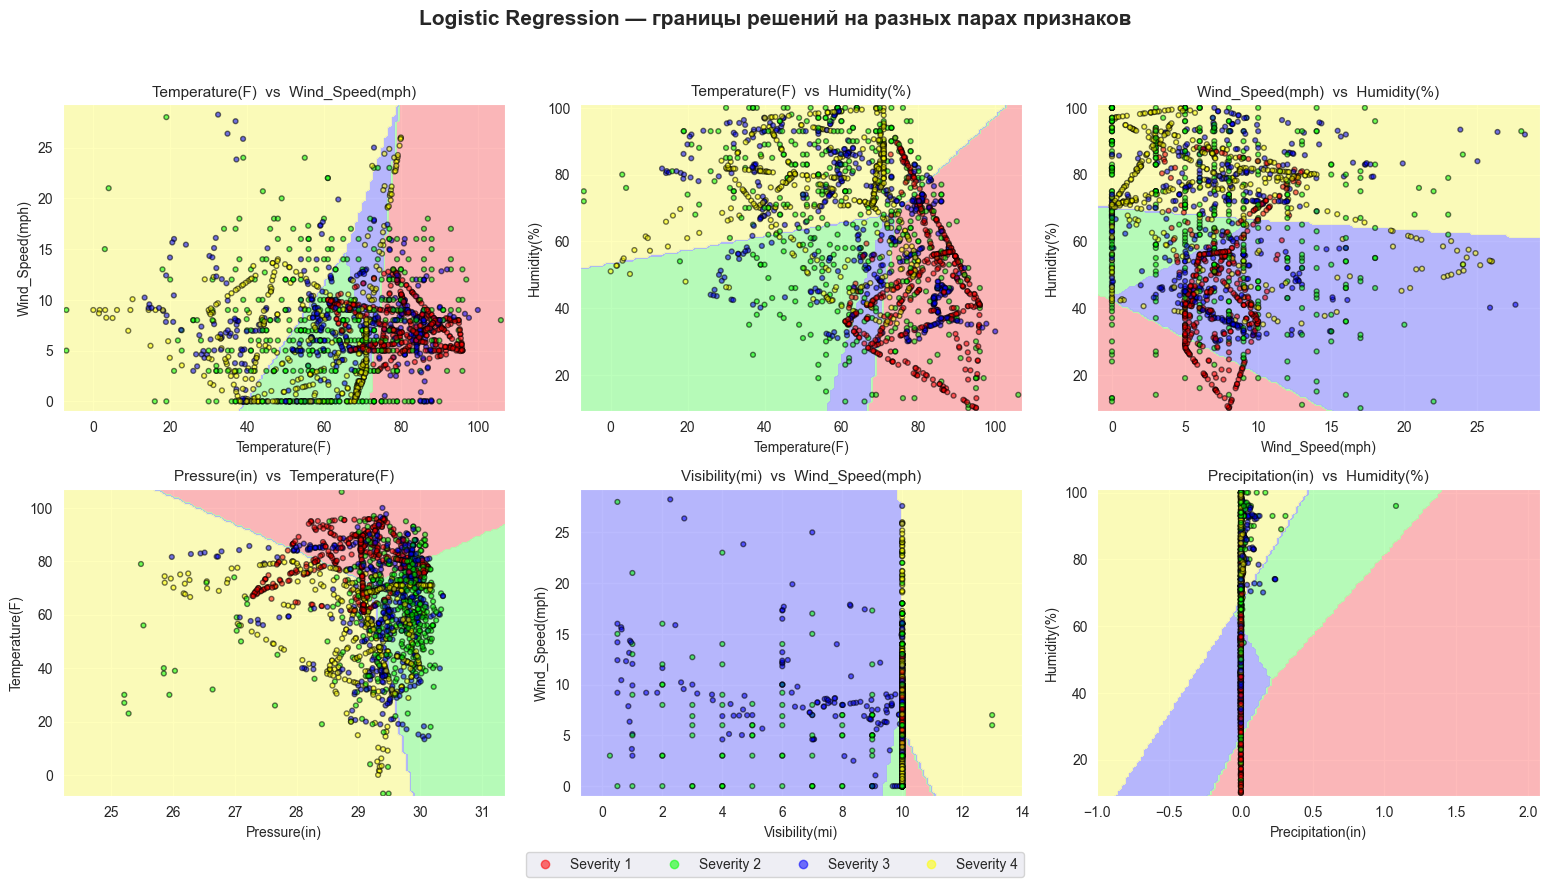

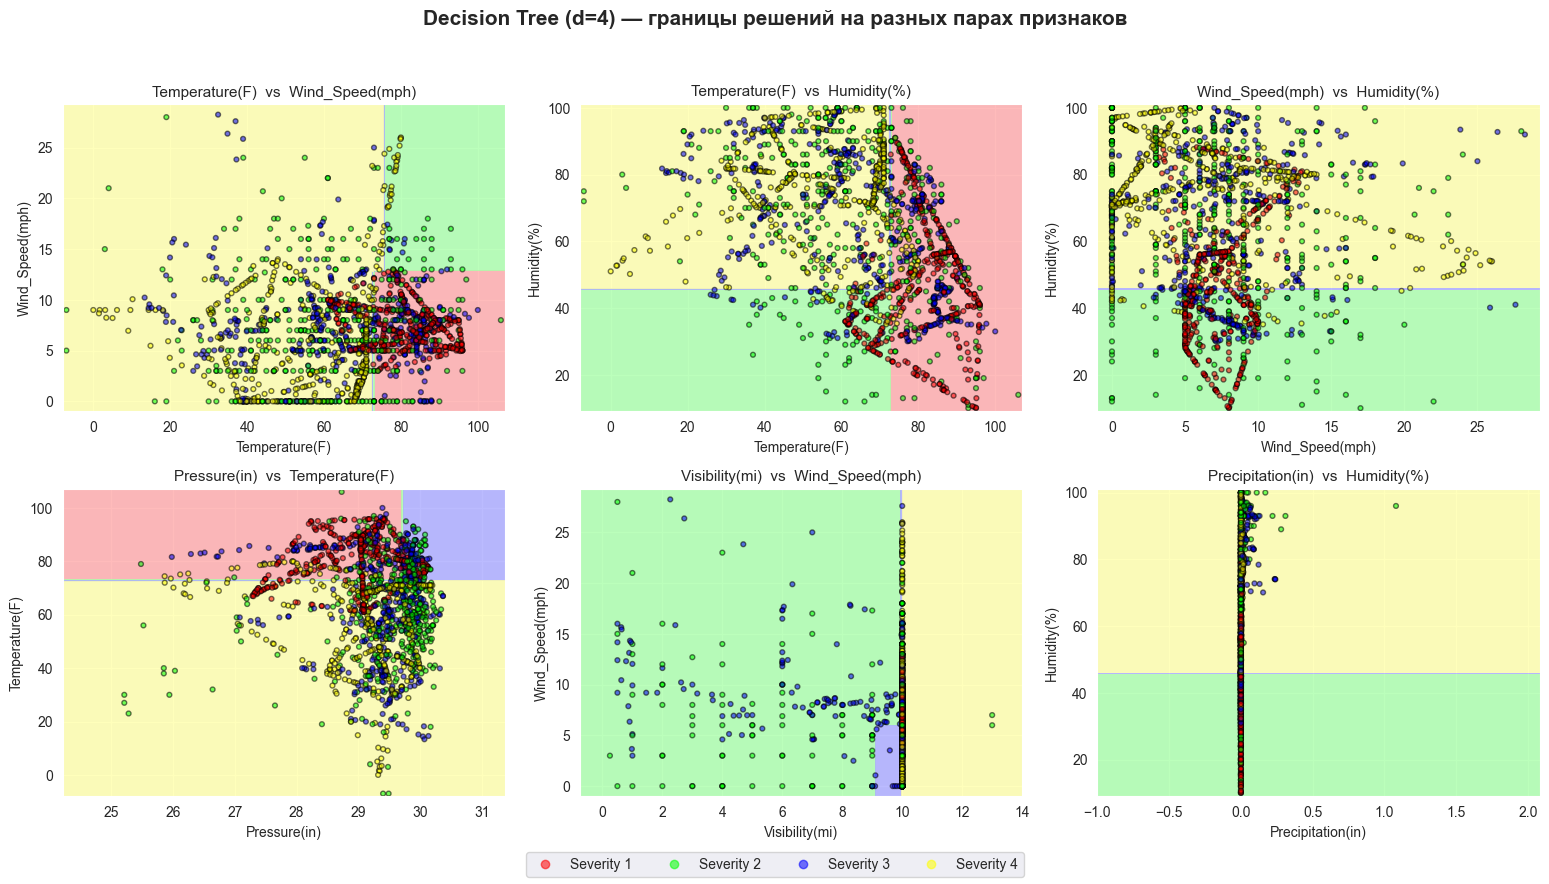

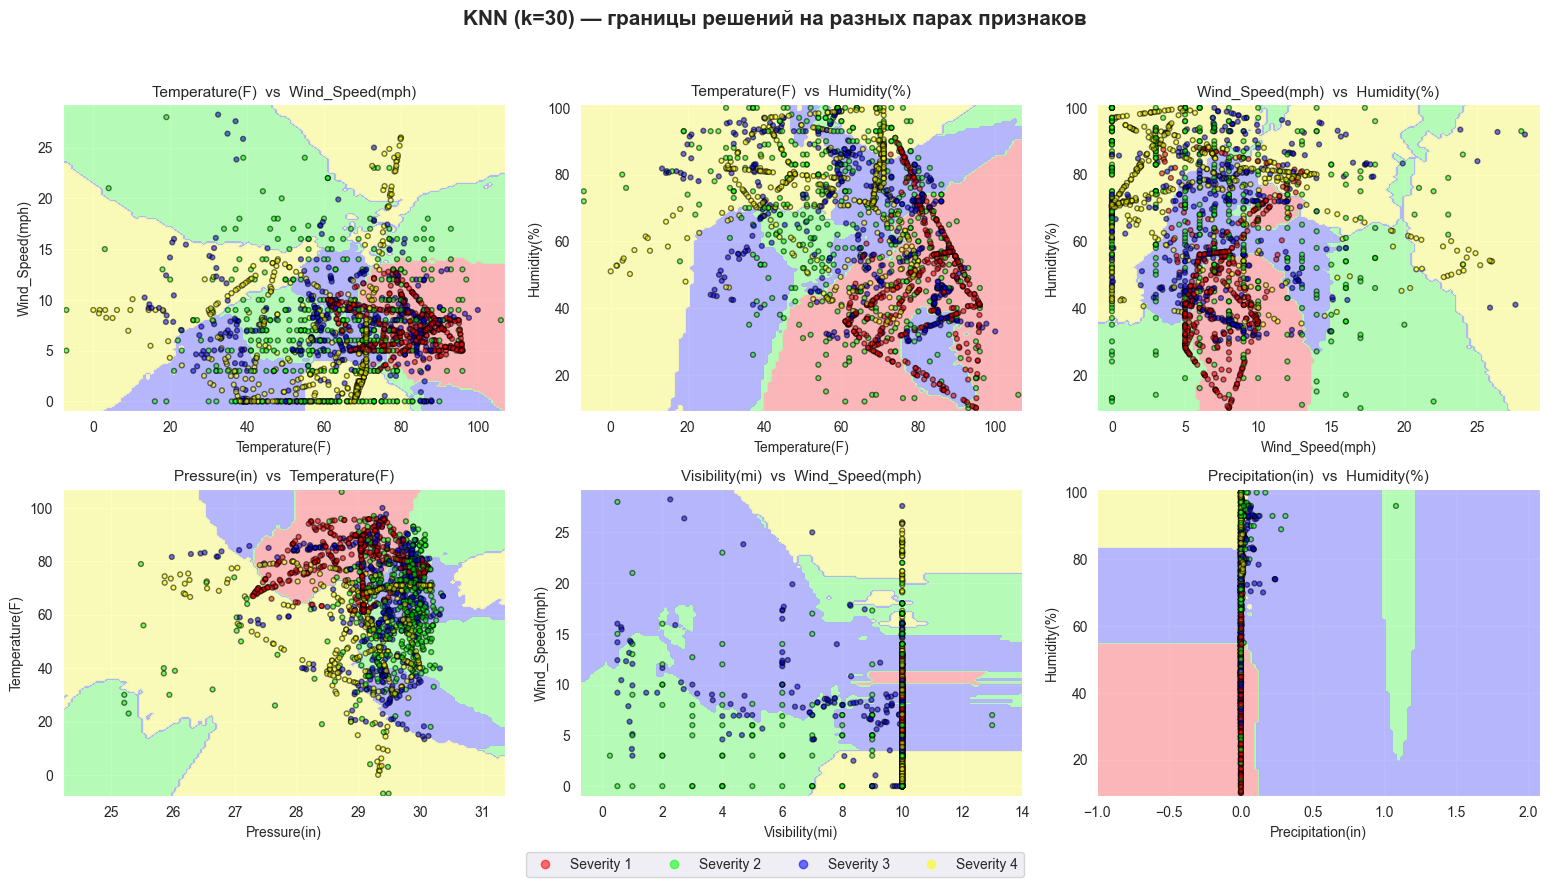

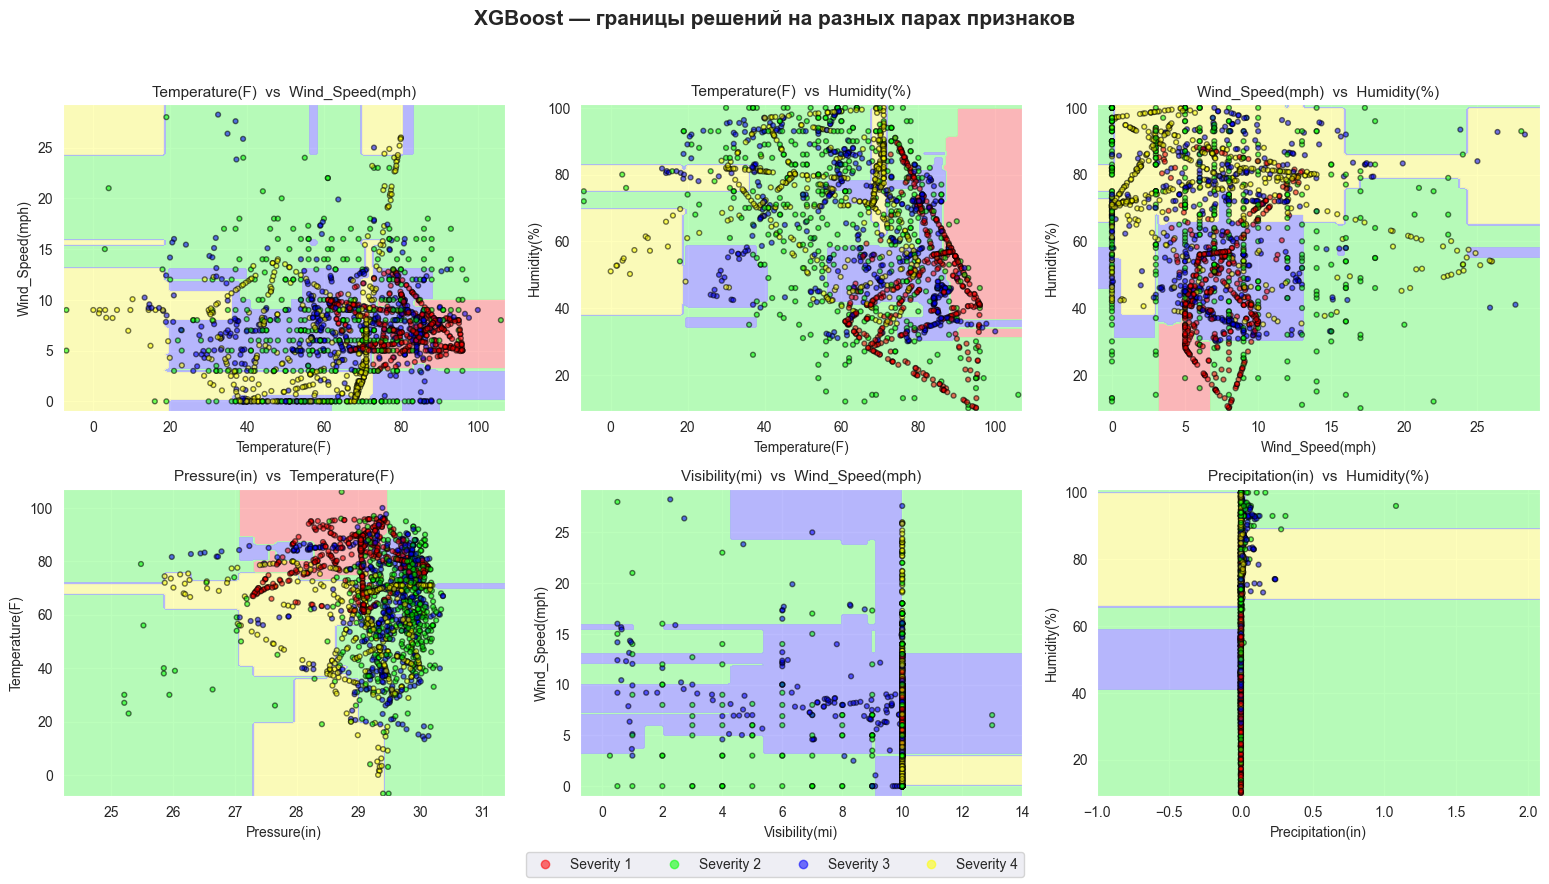

In [10]:
for name, model in models.items():
    plot_model_on_pairs(model, name)